# GGIS 403 Final Project Preliminary Analysis

**Topic:** Spatial Inequality in Access to Special Education Services in Illinois

This corrected preliminary notebook uses county as the spatial unit because the ISBE workbook includes county names but does not include latitude, longitude, or ZIP code.

In [1]:
# Install packages in Colab if needed
# !pip install geopandas mapclassify pyogrio openpyxl

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load ISBE Report Card workbook

In [2]:
isbe_path = "/content/drive/MyDrive/Colab Notebooks/2025-Report-Card-Public-Data-Set.xlsx"

sheets = pd.read_excel(isbe_path, sheet_name=None)
print("Loaded ISBE workbook. Sheets:", list(sheets.keys())[:10])

Loaded ISBE workbook. Sheets: ['Revision History', 'General', 'General (2)', 'ACT', 'DLM', 'DLM (2)', 'IAR', 'ISA', 'ELAMathScience', 'ELAMathScience (2)']


In [3]:
# Inspect possible IEP / disability columns
possible_cols = []
for sheet_name, df in sheets.items():
    for col in df.columns:
        c = str(col).lower()
        if any(k in c for k in ["iep", "disab", "special"]):
            possible_cols.append((sheet_name, col))

possible_cols[:50]

[('General', '% Student Enrollment - Children with Disabilities'),
 ('General', '% Student Enrollment - IEP'),
 ('General', '# Student Enrollment - Children with Disabilities'),
 ('General', '# Student Enrollment - IEP'),
 ('General', 'Student Mobility Rate - Children with Disabilities'),
 ('General', 'Student Mobility Rate - IEP'),
 ('General', 'High School Dropout Rate - Children with Disabilities'),
 ('General', 'High School Dropout Rate - IEP'),
 ('General', 'High School Dropout Count - Children with Disabilities'),
 ('General', 'High School Dropout Count - IEP'),
 ('General',
  'High School 4-Year Graduation Rate - Children with Disabilities'),
 ('General', 'High School 4-Year Graduation Rate - IEP'),
 ('General',
  'High School 4-Year Cohort Graduates - Children with Disabilities'),
 ('General', 'High School 4-Year Cohort Graduates - IEP'),
 ('General', 'High School 4-Year IEP Continuing Rate - Total'),
 ('General', 'High School 4-Year IEP Continuing Rate - Male'),
 ('General', '

## 2. Select and clean school data using county

In [4]:
school_sheet = "General"
school_name_col = "School Name"
county_col = "County"
sped_col = "% Student Enrollment - IEP"

schools_raw = sheets[school_sheet].copy()

# Keep only school-level rows if Level column exists
if "Level" in schools_raw.columns:
    schools_raw = schools_raw[
        schools_raw["Level"].astype(str).str.lower().str.contains("school", na=False)
    ]

schools = schools_raw[[school_name_col, county_col, sped_col]].copy()
schools = schools.rename(columns={
    school_name_col: "school_name",
    county_col: "county",
    sped_col: "iep_percent"
})

schools["county"] = schools["county"].astype(str).str.strip().str.title()
schools["iep_percent"] = pd.to_numeric(schools["iep_percent"], errors="coerce")
schools = schools.dropna(subset=["county"])
schools["has_iep_students"] = schools["iep_percent"].notna() & (schools["iep_percent"] > 0)

schools.head()

,school_name,county,iep_percent,has_iep_students
2,A-C Central Elementary School,Cass,12.1,True
3,A-C Central High School,Cass,NaN,False
4,A-C Central Middle School,Cass,14.0,True
6,Abingdon-Avon High Sch,Knox,15.2,True
7,Abingdon-Avon Middle Sch,Knox,22.2,True


## 3. Aggregate school-level IEP data by county

In [5]:
county_summary = schools.groupby("county").agg(
    school_count=("school_name", "count"),
    schools_with_iep=("has_iep_students", "sum"),
    mean_iep_percent=("iep_percent", "mean"),
    median_iep_percent=("iep_percent", "median")
).reset_index()

county_summary.head()

,county,school_count,schools_with_iep,mean_iep_percent,median_iep_percent
0,Adams,19,19,17.521053,16.90
1,Alexander,5,5,20.260000,20.60
2,Bond,8,7,23.671429,23.40
3,Boone,16,16,15.075000,13.85
4,Brown,3,3,16.300000,18.00


In [6]:
county_summary[["school_count", "schools_with_iep", "mean_iep_percent", "median_iep_percent"]].describe()

,school_count,schools_with_iep,mean_iep_percent,median_iep_percent
count,104.000000,104.000000,104.000000,104.000000
mean,36.798077,35.846154,17.815507,17.243269
std,125.076395,123.781029,3.179025,3.404416
min,2.000000,1.000000,3.400000,3.400000
25%,6.000000,6.000000,16.116644,15.337500
50%,13.000000,12.000000,17.627885,16.900000
75%,24.000000,23.000000,19.733333,18.825000
max,1240.000000,1226.000000,32.500000,32.500000


## 4. Load Illinois county boundaries and join data

In [7]:
county_url = "https://www2.census.gov/geo/tiger/TIGER2023/COUNTY/tl_2023_us_county.zip"
counties = gpd.read_file(county_url)

# Illinois STATEFP is 17
il_counties = counties[counties["STATEFP"] == "17"].copy()
il_counties = il_counties.rename(columns={"NAME": "county"})
il_counties["county"] = il_counties["county"].astype(str).str.strip().str.title()
il_counties = il_counties.to_crs("EPSG:26916")

county_map = il_counties.merge(county_summary, on="county", how="left")
county_map[["county", "school_count", "schools_with_iep", "mean_iep_percent"]].head()

,county,school_count,schools_with_iep,mean_iep_percent
0,Hancock,12.0,12.0,13.733333
1,Clay,8.0,8.0,17.950000
2,Wabash,5.0,5.0,16.660000
3,Mclean,53.0,51.0,19.056863
4,Bond,8.0,7.0,23.671429


In [8]:
# Check missing joins / missing IEP summaries
county_map[["county", "school_count", "mean_iep_percent"]].isna().sum()

,0
county,0
school_count,3
mean_iep_percent,3


## 5. Preliminary maps

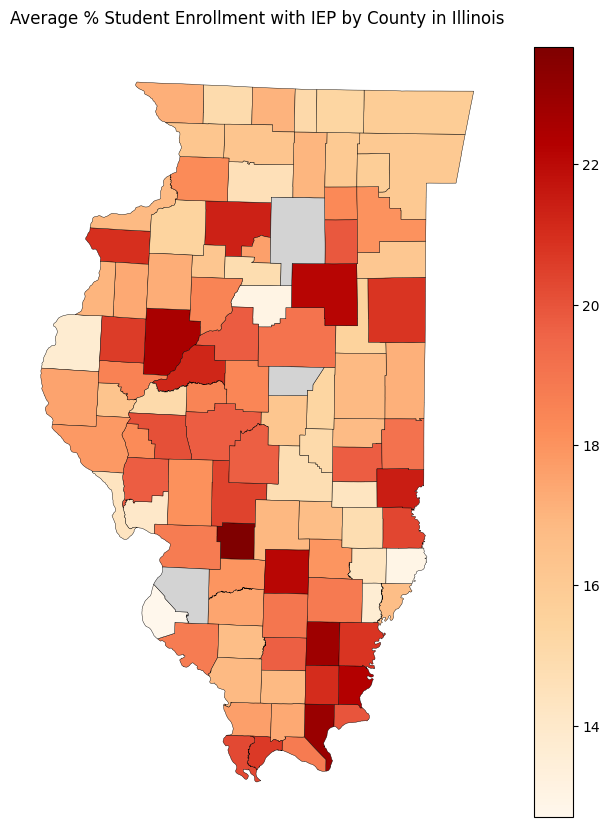

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))
county_map.plot(
    column="mean_iep_percent",
    cmap="OrRd",
    legend=True,
    ax=ax,
    linewidth=0.3,
    edgecolor="black",
    missing_kwds={"color": "lightgrey", "label": "Missing"}
)
ax.set_title("Average % Student Enrollment with IEP by County in Illinois")
ax.axis("off")
plt.show()

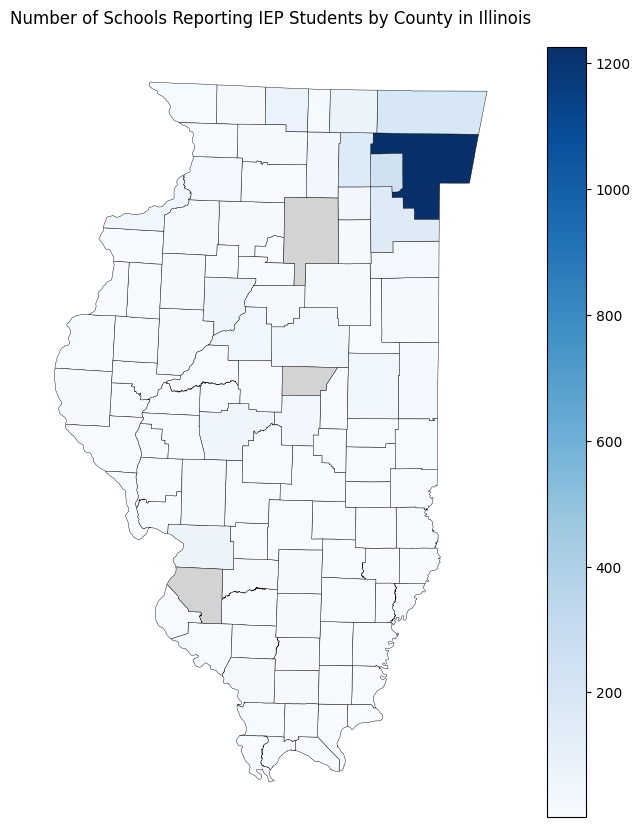

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))
county_map.plot(
    column="schools_with_iep",
    cmap="Blues",
    legend=True,
    ax=ax,
    linewidth=0.3,
    edgecolor="black",
    missing_kwds={"color": "lightgrey", "label": "Missing"}
)
ax.set_title("Number of Schools Reporting IEP Students by County in Illinois")
ax.axis("off")
plt.show()

## 6. Preliminary chart

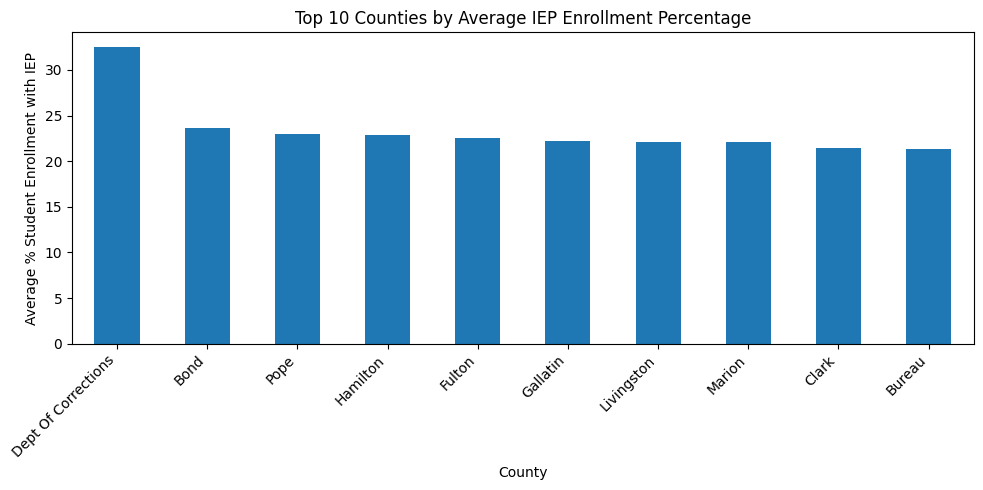

In [11]:
top_counties = county_summary.sort_values("mean_iep_percent", ascending=False).head(10)

top_counties.plot(
    kind="bar",
    x="county",
    y="mean_iep_percent",
    legend=False,
    figsize=(10, 5)
)
plt.ylabel("Average % Student Enrollment with IEP")
plt.xlabel("County")
plt.title("Top 10 Counties by Average IEP Enrollment Percentage")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
# Overall summary statistics for all counties

county_summary[["school_count", "schools_with_iep", "mean_iep_percent", "median_iep_percent"]].describe()

,school_count,schools_with_iep,mean_iep_percent,median_iep_percent
count,104.000000,104.000000,104.000000,104.000000
mean,36.798077,35.846154,17.815507,17.243269
std,125.076395,123.781029,3.179025,3.404416
min,2.000000,1.000000,3.400000,3.400000
25%,6.000000,6.000000,16.116644,15.337500
50%,13.000000,12.000000,17.627885,16.900000
75%,24.000000,23.000000,19.733333,18.825000
max,1240.000000,1226.000000,32.500000,32.500000


## 7. Notes for final report

This preliminary analysis uses county as the spatial unit because the current ISBE workbook does not include school latitude, longitude, or ZIP code. The maps are useful for showing county-level variation, but they are not yet a direct distance-based measure of access. For the final report, I may add ACS income / poverty variables and look for another school location dataset or geocode school addresses.